# 02 · Contracts: two record systems, amendments and values

**Stage 2, checklist questions 1, 3, 4 and 6.** Both contract files share one layout, but the rows were written by
two different systems: the old PWGSC contract-history system and the CanadaBuys system that replaced it. This
notebook measures how they differ, because that decides how they can be combined (stage 3), and checks what the
value fields mean.

**How a row's system is identified.** The `contractingEntityName` column holds one of two labels for the same
department: "Public Works and Government Services Canada" (old system) or "Department of Public Works and Government
Services (PSPC)" (new system). Section 1 shows that the label lines up exactly with which fields are filled, so it
is a reliable marker (`spendpipe.sources.record_system`).

Contracts from both files are **stacked** here, because notebook 01 showed that 405 contracts have rows in both.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from spendpipe import sources as S, eda
eda.apply_style()
pd.set_option("display.max_columns", 30, "display.width", 160, "display.max_colwidth", 60)

In [2]:
rows = S.parse_types(pd.concat([S.load("contracts_legacy"), S.load("contracts_current")], ignore_index=True))
rows["system"] = S.record_system(rows.contracting_entity)
pd.crosstab(rows.source, rows.system, margins=True)

system,new,old,All
source,,,
contracts_current,21477,1761,23238
contracts_legacy,18472,467679,486151
All,39949,469440,509389


## 1. Which fields does each system fill?

Share of rows with a value, by system. Fields the dashboard depends on are listed first.

In [3]:
fields = ["unspsc", "gsin", "instrument_type", "procurement_method", "limited_tendering_reason", "selection_criteria",
          "solicitation_number", "notice_type", "status", "start_date", "award_date", "supplier_standardized_name",
          "supplier_legal_name", "client_department", "contract_amount", "total_value"]
fill = rows.groupby("system")[fields].agg(lambda s: s.notna().mean()).T * 100
fill.round(1).style.format("{:.1f}%").background_gradient(cmap="Blues", vmin=0, vmax=100)

system,new,old
unspsc,100.0%,0.0%
gsin,4.0%,100.0%
instrument_type,100.0%,0.0%
procurement_method,65.9%,100.0%
limited_tendering_reason,72.6%,16.9%
selection_criteria,89.4%,83.0%
solicitation_number,100.0%,0.0%
notice_type,100.0%,0.0%
status,100.0%,0.0%
start_date,100.0%,0.0%


The split is sharp. Old-system rows never carry UNSPSC, instrument type, solicitation number, notice type, status
or start date. New-system rows carry them all, and GSIN rarely. Both fill the procurement method, supplier legal
name, client department and value fields. Those shared fields are what a combined 2009-2026 view can rely on
without translation.

Can a single contract have rows from both systems?

In [4]:
per_contract = rows.groupby("contract_number").system.nunique()
print(f"contracts: {len(per_contract):,} | with rows from both systems: {(per_contract > 1).sum():,}")
first = S.first_rows(rows)
print("system of each contract's first row:", first.system.value_counts().to_dict())

contracts: 224,307 | with rows from both systems: 4,918


system of each contract's first row: {'old': 206579, 'new': 17728}


## 2. Contracts with no original record

The original award is amendment `000`. A contract without one shows only amendments, so its award date and
original amount are unknown. Hypothesis: these are amendments to contracts awarded **before** the data starts
(Jan 2009). If so, their earliest visible activity should bunch up at the start of the file.

In [5]:
has_000 = rows.groupby("contract_number").amendment_number.apply(lambda s: s.eq("000").any())
no_orig = has_000[~has_000].index
print(f"contracts with no 000 record: {len(no_orig):,} of {len(has_000):,} ({len(no_orig) / len(has_000):.1%})")
sub = rows[rows.contract_number.isin(no_orig)]
earliest = sub.groupby("contract_number")[["award_date", "amendment_date"]].min()
earliest_activity = earliest.min(axis=1)
print(f"  with an award date on some row: {earliest.award_date.notna().sum():,}")
print("  award year where known:", earliest.award_date.dt.year.value_counts().sort_index().head(6).to_dict())
print("  year of earliest visible activity:", earliest_activity.dt.year.value_counts().sort_index().to_dict())

contracts with no 000 record: 29,186 of 224,307 (13.0%)


  with an award date on some row: 5,799
  award year where known: {2009.0: 10, 2010.0: 2, 2011.0: 12, 2012.0: 14, 2013.0: 29, 2014.0: 78}
  year of earliest visible activity: {2009: 11137, 2010: 2721, 2011: 1085, 2012: 800, 2013: 1108, 2014: 1444, 2015: 905, 2016: 1074, 2017: 1015, 2018: 1667, 2019: 1399, 2020: 798, 2021: 1177, 2022: 740, 2023: 869, 2024: 697, 2025: 411, 2026: 139}


In [6]:
lowest = first.loc[no_orig, "amendment_number"]
seq = S.amendment_seq(lowest)
print("lowest visible amendment:", {"001": int((seq == 1).sum()), "002-009": int(seq.between(2, 9).sum()),
                                    "010+": int(seq.between(10, 999).sum()), "letter codes (T01, S01...)": int((seq == 1000).sum())})
print("system of first row:", first.loc[no_orig, "system"].value_counts().to_dict())
mixed = per_contract[per_contract > 1].index
print(f"of the {len(mixed):,} contracts with rows from both systems, {mixed.isin(no_orig).sum():,} have no 000 record")

lowest visible amendment: {'001': 20842, '002-009': 7239, '010+': 619, 'letter codes (T01, S01...)': 486}
system of first row: {'old': 26191, 'new': 2995}


of the 4,918 contracts with rows from both systems, 1,637 have no 000 record


## 3. Amendment numbering

In [7]:
odd = rows.amendment_number[~rows.amendment_number.str.fullmatch(r"\d{3}")]
print(f"rows whose amendment number is not 3 digits: {len(odd):,}")
print(odd.value_counts().head(12).to_dict())
print("by system:", rows.loc[odd.index, "system"].value_counts().to_dict())

rows whose amendment number is not 3 digits: 4,408
{'T01': 3381, 'S01': 874, 'S02': 51, '51': 24, '52': 24, '65': 9, '64': 9, 'S03': 5, 'T02': 4, '15': 2, '08': 2, '39': 2}
by system: {'old': 4408}


## 4. What do the value fields mean?

`totalContractValue` should be one figure per contract (the data dictionary calls it the contract's total value).
`contractAmount` is the amount on each record, and v1 could not tell whether amendment amounts are **changes** (deltas)
or **running totals**. If they are deltas, adding them up should give the total value.

In [8]:
g = rows.groupby("contract_number")
multi = g.size() > 1
tcv = g.total_value.first()
delta_sum = g.contract_amount.sum(min_count=1)
orig = first.contract_amount.where(first.amendment_number.eq("000"))
checks = pd.DataFrame({
    "contracts": [len(tcv), int(multi.sum())],
    "total value identical on every row": [g.total_value.nunique(dropna=False).eq(1).mean(), None],
    "sum of amounts == total value (±$1)": [None, (delta_sum - tcv).abs().le(1)[multi].mean()],
    "original amount == total value (±$1)": [None, (orig - tcv).abs().le(1)[multi].mean()],
}, index=["all contracts", "contracts with amendments"])
checks

,contracts,total value identical on every row,sum of amounts == total value (±$1),original amount == total value (±$1)
all contracts,224307,1.0,NaN,NaN
contracts with amendments,96337,NaN,0.87332,0.294466


In [9]:
by_sys = pd.DataFrame({"multi": multi, "sums_match": (delta_sum - tcv).abs().le(1), "has_original": has_000,
                       "system": first.system})[multi]
print("sum of amounts == total value, by system of the first row and whether the original record is present:")
print(by_sys.groupby(["system", "has_original"]).sums_match.agg(["mean", "size"])
      .rename(columns={"mean": "share", "size": "contracts"}).round(3))
neg = rows[rows.contract_amount < 0]
print(f"\nnegative contractAmount rows: {len(neg):,}; on amendment rows: {(neg.amendment_number != '000').mean():.1%}")

sum of amounts == total value, by system of the first row and whether the original record is present:
                     share  contracts
system has_original                  
new    False         0.318       1062
       True          0.747       5085
old    False         0.504      16274
       True          0.971      73916

negative contractAmount rows: 20,007; on amendment rows: 100.0%


In [10]:
example = by_sys[~by_sys.sums_match & by_sys.has_original].index[0]
rows.loc[rows.contract_number == example, ["contract_number", "amendment_number", "amendment_date", "contract_amount",
                                           "total_value", "system"]].sort_values("amendment_number")

,contract_number,amendment_number,amendment_date,contract_amount,total_value,system
166099,01044-150366/001/XL,000,NaT,35092.00,256306.88,old
355299,01044-150366/001/XL,001,2016-03-17,24096.00,256306.88,old
374194,01044-150366/001/XL,002,2017-03-24,25485.00,256306.88,old
390343,01044-150366/001/XL,003,2018-03-15,26569.00,256306.88,old
409168,01044-150366/001/XL,004,2019-03-19,27897.00,256306.88,old
422785,01044-150366/001/XL,005,2020-01-30,29292.00,256306.88,old
439990,01044-150366/001/XL,006,2021-02-15,29292.00,256306.88,old
485185,01044-150366/001/XL,007,2026-04-15,29291.86,256306.88,new


**Contract-level values.** Using `totalContractValue` once per contract:

In [11]:
v = tcv
print(f"contracts {len(v):,} | total ${v.sum() / 1e9:,.1f}B | zero {(v == 0).sum():,} | negative {(v < 0).sum():,} | "
      f">= $1B {(v >= 1e9).sum():,} | share of positive value in contracts >= $1B {v[v >= 1e9].sum() / v[v > 0].sum():.1%}")
top = first.assign(total_value=tcv, award_year=first.award_date.dt.year.astype("Int64"))[["supplier_legal_name", "total_value",
                                                                          "award_year", "system"]]
top.nlargest(10, "total_value").style.format({"total_value": "${:,.0f}"})

contracts 224,307 | total $336.8B | zero 25,296 | negative 74 | >= $1B 35 | share of positive value in contracts >= $1B 27.0%


,supplier_legal_name,total_value,award_year,system
contract_number,,,,
CW2465774,Chantier Davie Canada Inc.,"$13,044,299,191",2026,new
W847S-150030/001/AO,Irving Shipbuilding Inc\Les chantiers maritime Irving,"$6,123,999,189",2014,old
EP008-112560/003/GC,BGIS GLOBAL INTEGRATED SOLUTIONS CANADA LP/BGIS SOLUTIONS GLOBALES INTEGREES CANADA S.E.C.,"$5,723,000,000",2014,old
QA002-142501/001/NB,Groupe Signature sur le Saint-Laurent,"$5,048,022,958",2015,old
W847L-200124/001/APC,General Dynamics Land Systems - Canada Corporation,"$4,037,481,752",2019,old
EP635-173247/001/NB,ESAP Project Co Limited Partnership,"$4,020,555,855",2019,old
F7017-251202/001/NQ,Chantier Davie Canada Inc.,"$3,745,829,208",2025,old
EP748-151886/001/FQ,"PCL/ ED, a Joint Venture","$3,504,074,067",2017,old
W847S-180070/002/JSS,Vancouver Shipyards Co. Ltd.,"$3,397,262,476",2020,old


## 5. Do the two systems record the same kind of contract?

If the new system simply replaced the old one, contract sizes should look alike. Compare the distribution of
positive contract values by system (log scale, so $10K, $100K and $1M are evenly spaced).

In [12]:
size = pd.DataFrame({"value": tcv, "system": first.system}).query("value > 0")
summary = size.groupby("system").value.describe(percentiles=[.25, .5, .75, .9])[["count", "25%", "50%", "75%", "90%"]]
summary["share under $25K"] = size.groupby("system").value.apply(lambda s: (s < 25_000).mean())
summary.style.format({"count": "{:,.0f}", "25%": "${:,.0f}", "50%": "${:,.0f}", "75%": "${:,.0f}", "90%": "${:,.0f}",
                      "share under $25K": "{:.1%}"})

,count,25%,50%,75%,90%,share under $25K
system,,,,,,
new,"12,845","$70,000","$212,205","$783,782","$2,840,930",7.9%
old,"186,092","$21,784","$59,077","$253,975","$1,000,000",27.9%


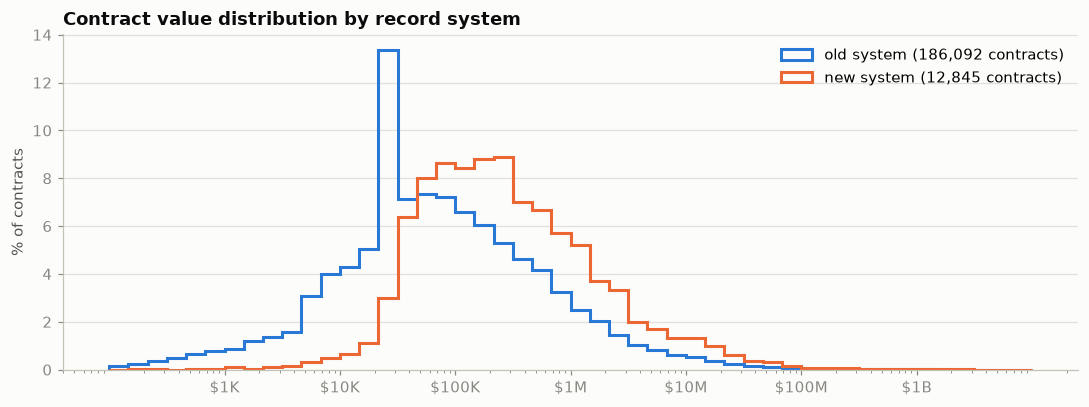

In [13]:
import numpy as np
fig, ax = plt.subplots(figsize=(10, 3.8))
bins = np.logspace(2, 10, 49)
for sys_ in ["old", "new"]:
    vals = size.loc[size.system == sys_, "value"]
    ax.hist(vals, bins=bins, weights=np.full(len(vals), 100 / len(vals)), histtype="step", linewidth=2,
            color=eda.SYSTEM_COLORS[sys_], label=f"{sys_} system ({len(vals):,} contracts)")
ax.set_xscale("log")
ax.set_xticks([1e3, 1e4, 1e5, 1e6, 1e7, 1e8, 1e9], ["$1K", "$10K", "$100K", "$1M", "$10M", "$100M", "$1B"])
ax.set_ylabel("% of contracts")
ax.set_title("Contract value distribution by record system")
ax.legend()
fig.tight_layout()

**Fair comparison.** Old-system contracts are mostly older, so the gap above mixes "which system" with "which
year". The cleaner test compares the two systems **within the same fiscal years**, when both were in use.

In [14]:
d = pd.DataFrame({"value": tcv, "system": first.system, "award": g.award_date.min()}).query("value > 0")
d["fy"] = d.award.dt.year - (d.award.dt.month < 4)
same = d[d.fy.between(2020, 2023)]
cmp_ = same.groupby(["fy", "system"]).value.agg(contracts="size", median="median",
                                                 under_25k=lambda s: (s < 25_000).mean()).unstack("system")
cmp_.index = [f"FY{int(y)}-{int(y + 1) % 100:02d}" for y in cmp_.index]
cmp_.style.format({c: ("{:,.0f}" if c[0] == "contracts" else "${:,.0f}" if c[0] == "median" else "{:.1%}")
                   for c in cmp_.columns})

## 6. Contracts and value per fiscal year

Each contract is placed by the **earliest award date on any of its rows** (a provisional rule for EDA; the real rule
is a stage 3 decision) and coloured by the system of its first row. Government of Canada fiscal years run April-March.
FY2008-09 holds only Jan-Mar 2009 and FY2026-27 is in progress; both are partial. Contracts with no award date are
left out.

contracts without any award date (left out): 23,387


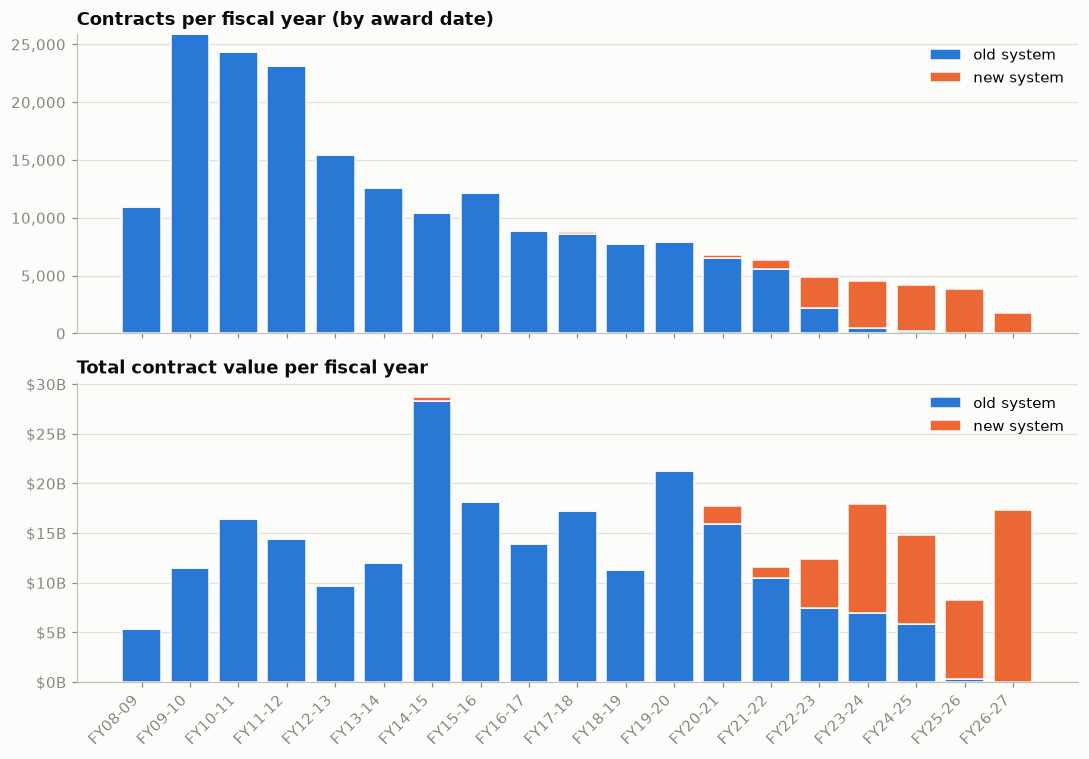

In [15]:
def fiscal_year(d):
    return (d.dt.year - (d.dt.month < 4)).astype("Int64")

contracts = pd.DataFrame({"award_date": g.award_date.min(), "value": tcv, "system": first.system})
contracts["fy"] = fiscal_year(contracts.award_date)
yearly = contracts.dropna(subset=["fy"]).pivot_table(index="fy", columns="system", values="value",
                                                     aggfunc=["size", "sum"], fill_value=0)
print(f"contracts without any award date (left out): {contracts.award_date.isna().sum():,}")
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for ax, (agg, title, fmt) in zip(axes, [("size", "Contracts per fiscal year (by award date)", eda.thousands()),
                                        ("sum", "Total contract value per fiscal year", eda.money("B"))]):
    bottom = np.zeros(len(yearly))
    for sys_ in ["old", "new"]:
        vals = yearly[(agg, sys_)].values
        ax.bar(yearly.index.astype(int), vals, bottom=bottom, color=eda.SYSTEM_COLORS[sys_], width=0.8,
               edgecolor=eda.SURFACE, linewidth=1, label=f"{sys_} system")
        bottom += vals
    ax.set_title(title)
    ax.yaxis.set_major_formatter(fmt)
    ax.legend(loc="upper right")
axes[1].set_xticks(yearly.index.astype(int), [f"FY{y % 100:02d}-{(y + 1) % 100:02d}" for y in yearly.index.astype(int)],
                   rotation=45, ha="right")
fig.tight_layout()

In [16]:
table = pd.DataFrame({"contracts": yearly["size"].sum(axis=1), "value $B": yearly["sum"].sum(axis=1) / 1e9,
                      "new-system share of contracts": yearly[("size", "new")] / yearly["size"].sum(axis=1)})
table.index = [f"FY{y}-{(y + 1) % 100:02d}" for y in table.index.astype(int)]
table.style.format({"contracts": "{:,.0f}", "value $B": "{:,.1f}", "new-system share of contracts": "{:.0%}"})

,contracts,value $B,new-system share of contracts
FY2008-09,"10,948",5.3,0%
FY2009-10,"25,883",11.5,0%
FY2010-11,"24,334",16.4,0%
FY2011-12,"23,170",14.4,0%
FY2012-13,"15,467",9.7,0%
FY2013-14,"12,607",12.0,0%
FY2014-15,"10,380",28.7,0%
FY2015-16,"12,187",18.1,0%
FY2016-17,"8,906",13.9,0%
FY2017-18,"8,811",17.2,2%


## Findings

1. **Two record systems, identified by the contracting-entity label.** 469,440 rows are old-system and 39,949 are
   new-system. Old-system rows have no UNSPSC, instrument type, solicitation number, notice type, status or start
   date. Fields both systems fill are procurement method, supplier legal name, client department and the value
   fields. In new-system rows the procurement method is missing on 34.1% of rows and the limited-tendering reason
   on 27.4%, so "method not reported" needs a rule in stage 4.
2. **The switch was gradual, not a cutover.** New-system contracts are 2% of a year's contracts in FY2017-18, 13% in
   FY2021-22, 54% in FY2022-23 and 99% in FY2025-26. 4,918 contracts have rows from both systems: contracts started
   in the old system and later amended in the new one.
3. **The drop in contract counts is not caused by the system change.** Counts fall from 25,883 (FY2009-10) to
   6,394 (FY2021-22) almost entirely within the old system, while yearly value stays between about $10B and $29B.
   Within the same fiscal years, the two systems record contracts of similar size (FY2021-22 median $157K new vs
   $209K old; share under $25K 6.6% vs 5.1%). The large overall gap in median size ($59K vs $212K) reflects timing:
   small contracts became rarer over 2009-2020. *Corrects an earlier reading that the systems record different
   contract sizes.* Why small contracts fell is a stage 3 question; nothing here says why.
4. **Contracts with no original record:** 29,186 of 224,307 (13.0%). 71% start at amendment 001, so usually only
   the original is missing. 38% have their earliest visible activity in 2009, consistent with awards before the
   data starts, but the rest are spread over every year, so the pre-2009 explanation covers only part of them.
5. **Amendment numbers:** 4,408 rows are not three digits (`T01` 3,381, `S01` 874, plus a few two-digit codes), all
   in the old system.
6. **Values.** `totalContractValue` is identical on every row of all 224,307 contracts, so it is a per-contract
   figure and must not be summed across rows. **Amendment amounts are changes (deltas):** where the original record
   is present, amounts sum to the total in 97.1% of amended old-system contracts and 74.7% of new-system ones. The
   example of a mismatch is short by exactly one more yearly payment, which suggests a missing record, not running
   totals. Negative amounts (20,007 rows) occur only on amendments. This supports v1's unvalidated "growth after
   award" metric for old-system contracts. New-system contracts need a closer look (stage 4).
7. **Scale:** 224,307 contracts, $336.8B total value; 35 contracts of $1B or more hold 27.0% of positive value.
8. **Threshold spike:** about 13% of old-system contracts fall in the single histogram bin from $21.5K to $31.6K,
   far above its neighbours. A reporting or approval threshold near $25K is a possible cause; to be checked in
   stage 4, not assumed.